### Import Data & Library

### Install Library

In [29]:
!pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

### Import Library

In [30]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### Import Data

In [31]:
df = pd.read_csv('HR Employee.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# EDA

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

### Analisis Deskriptif

In [33]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


### Missing Value

In [34]:
print("Total missing :", df.isna().sum().sum())
print("Duplikat baris:", df.duplicated().sum())

Total missing : 0
Duplikat baris: 0


### Distribusi Attrition

In [35]:
# Distribusi target
tgt = df["Attrition"].map({"Yes": 1, "No": 0}) if df["Attrition"].dtype == object else df["Attrition"]
counts = tgt.value_counts().sort_index()
print(counts, "\nProporsi:\n", tgt.value_counts(normalize=True).round(4))

Attrition
0    1233
1     237
Name: count, dtype: int64 
Proporsi:
 Attrition
0    0.8388
1    0.1612
Name: proportion, dtype: float64


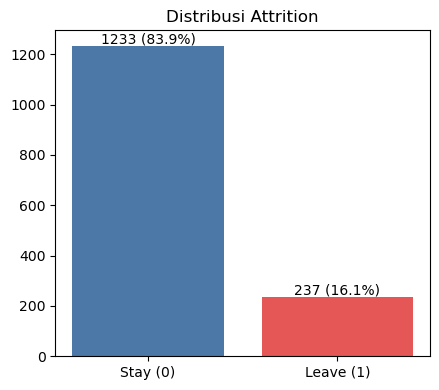

Imbalance ratio (mayoritas:minoritas) = 5.20 : 1


In [36]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.bar(["Stay (0)", "Leave (1)"], counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, f"{v} ({v/len(tgt):.1%})", ha="center")
ax.set_title("Distribusi Attrition"); plt.tight_layout(); plt.show()
print(f"Imbalance ratio (mayoritas:minoritas) = {counts[0]/counts[1]:.2f} : 1")

### Feature Engineering

In [37]:
# Buang kolom ID/konstan jika masih ada
drop_cols = [c for c in ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"] if c in df.columns]
df = df.drop(columns=drop_cols)

# Target 0/1 (hanya dikonversi jika masih teks)
if df["Attrition"].dtype == object:
    df["Attrition"] = (df["Attrition"] == "Yes").astype(int)
assert set(df["Attrition"].unique()) <= {0, 1}
print("Proporsi Attrition:", df["Attrition"].mean().round(4))   # harus ~0.16

# Fitur turunan
df["IncomePerYearExp"] = df["MonthlyIncome"] / (df["TotalWorkingYears"] + 1)
df["PromotionGap"]     = df["YearsSinceLastPromotion"] / (df["YearsAtCompany"] + 1)
df["SatisfactionMean"] = df[["JobSatisfaction", "EnvironmentSatisfaction",
                             "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)

# Pengelompokan tipe fitur (dipakai seluruh anggota)
CONT = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome",
        "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears",
        "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager",
        "IncomePerYearExp", "PromotionGap", "SatisfactionMean"]
ORD  = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
        "JobSatisfaction", "PerformanceRating", "RelationshipSatisfaction",
        "StockOptionLevel", "WorkLifeBalance"]
CAT  = ["BusinessTravel", "Department", "EducationField", "Gender",
        "JobRole", "MaritalStatus", "OverTime"]

missing = [c for c in CONT + ORD + CAT if c not in df.columns]
extra   = [c for c in df.columns if c not in CONT + ORD + CAT + ["Attrition"]]
assert not missing, f"Kolom hilang: {missing}"
print("Kolom tidak terpakai:", extra)    # idealnya []

Proporsi Attrition: 0.1612
Kolom tidak terpakai: []


### Korelasi Data

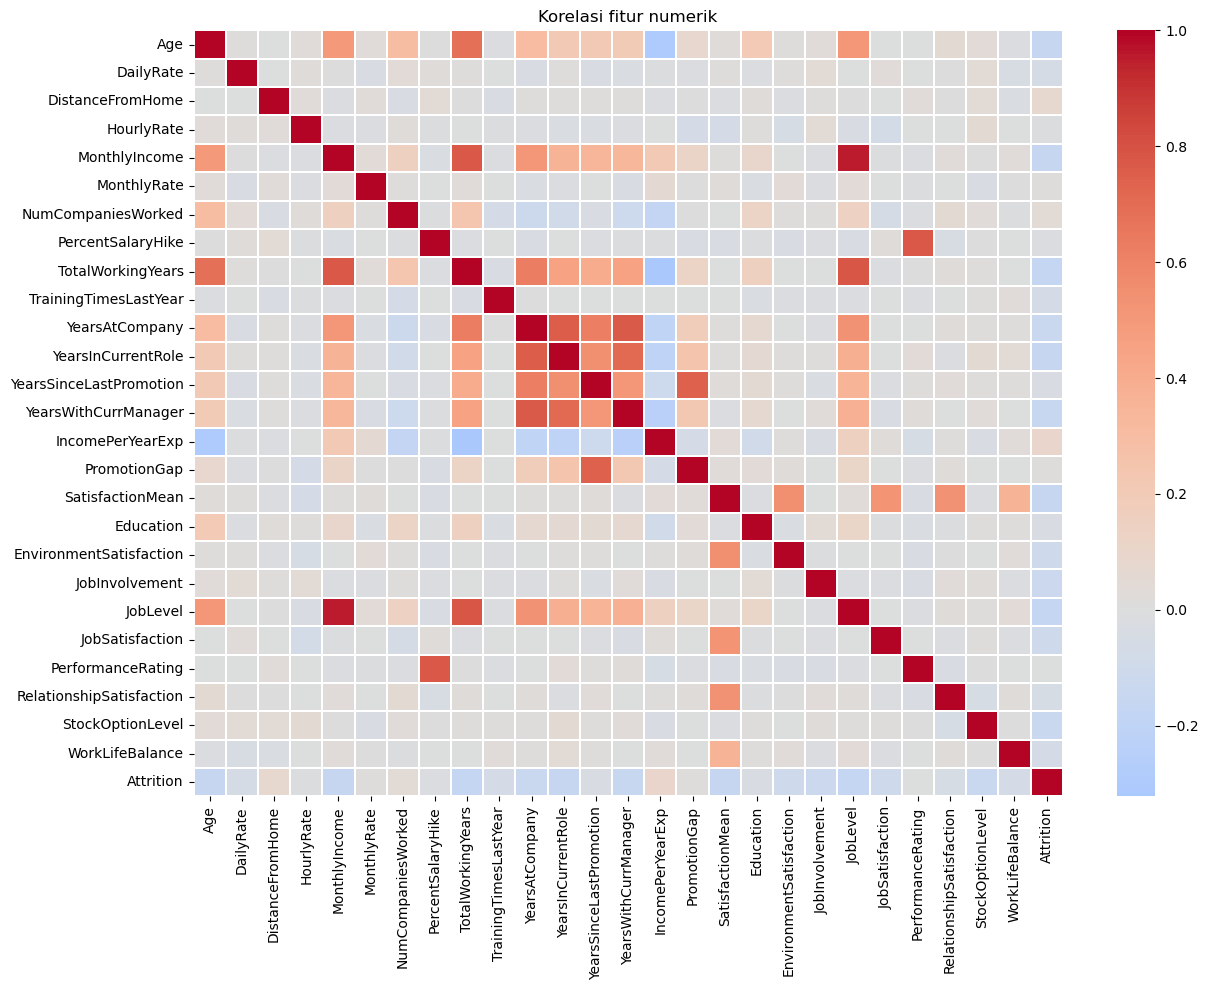

10 fitur paling berkorelasi dengan Attrition:
 TotalWorkingYears      -0.171
JobLevel               -0.169
YearsInCurrentRole     -0.161
MonthlyIncome          -0.160
Age                    -0.159
SatisfactionMean       -0.159
YearsWithCurrManager   -0.156
StockOptionLevel       -0.137
YearsAtCompany         -0.134
JobInvolvement         -0.130
Name: Attrition, dtype: float64

Pasangan korelasi > 0.7:
 MonthlyIncome            JobLevel                0.950
TotalWorkingYears        JobLevel                0.782
PercentSalaryHike        PerformanceRating       0.774
MonthlyIncome            TotalWorkingYears       0.773
YearsAtCompany           YearsWithCurrManager    0.769
                         YearsInCurrentRole      0.759
YearsSinceLastPromotion  PromotionGap            0.745
YearsInCurrentRole       YearsWithCurrManager    0.714
dtype: float64


In [38]:
num_cols = CONT + ORD
corr = df[num_cols + ["Attrition"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=.3)
plt.title("Korelasi fitur numerik"); plt.tight_layout(); plt.show()

top = corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False).head(10)
print("10 fitur paling berkorelasi dengan Attrition:\n", top.round(3))

# Pasangan fitur sangat berkorelasi (indikasi multikolinearitas)
c = corr.drop("Attrition").drop(columns="Attrition").abs()
pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
           .sort_values(ascending=False))
print("\nPasangan korelasi > 0.7:\n", pairs[pairs > 0.7].round(3))

                         n_outlier  persen
TrainingTimesLastYear          238   16.19
MonthlyIncome                  114    7.76
YearsSinceLastPromotion        107    7.28
YearsAtCompany                 104    7.07
TotalWorkingYears               63    4.29
NumCompaniesWorked              52    3.54
IncomePerYearExp                43    2.93
SatisfactionMean                36    2.45
YearsInCurrentRole              21    1.43
YearsWithCurrManager            14    0.95
Age                              0    0.00
PercentSalaryHike                0    0.00
HourlyRate                       0    0.00
DailyRate                        0    0.00
MonthlyRate                      0    0.00
DistanceFromHome                 0    0.00
PromotionGap                     0    0.00


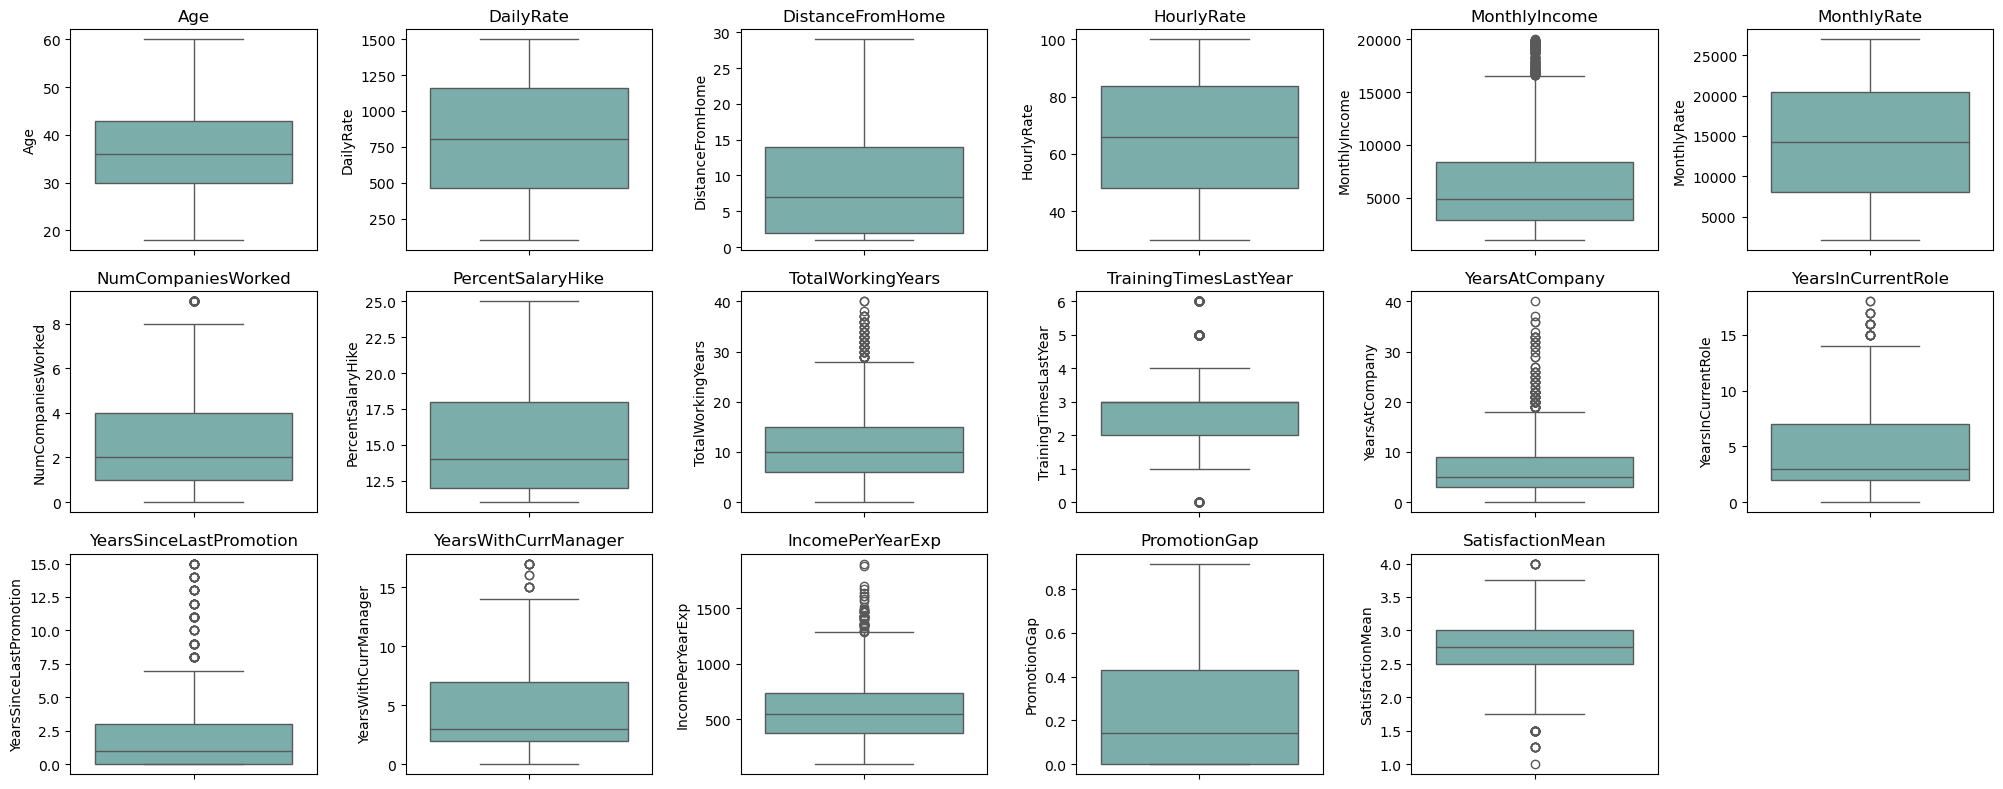

In [39]:
# Outlier (metode IQR): hanya dilaporkan, tidak dibuang
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()

out_tbl = pd.DataFrame({"n_outlier": {c: iqr_outliers(df[c]) for c in CONT}})
out_tbl["persen"] = (out_tbl["n_outlier"] / len(df) * 100).round(2)
print(out_tbl.sort_values("n_outlier", ascending=False))

fig, axes = plt.subplots(3, 6, figsize=(20, 8)); axes = axes.ravel()
for ax, col in zip(axes, CONT):
    sns.boxplot(y=df[col], ax=ax, color="#72B7B2"); ax.set_title(col)
for ax in axes[len(CONT):]: ax.axis("off")
plt.tight_layout(); plt.show()

# Pembuatan Model

### Split Data

In [40]:
SEED = 42

X = df.drop(columns="Attrition")
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Attrition train:", y_train.mean().round(4), "| test:", y_test.mean().round(4))

Train: (1176, 33) | Test: (294, 33)
Attrition train: 0.1616 | test: 0.1599


### Pembuatan Fungsi Model Baseline dan Pipeline

In [41]:
def make_preprocessor(extra_num=()):
    """Scaling fitur numerik + one-hot kategorikal. Di-fit hanya pada data train tiap fold."""
    return ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD + list(extra_num)),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def make_model(name, class_weight=None):
    if name == "LogReg":
        return LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=SEED)
    if name == "RandForest":      # parameter default (baseline)
        return RandomForestClassifier(class_weight=class_weight, random_state=SEED, n_jobs=-1)
    raise ValueError(name)

def build_pipeline(model_name, imb=None):
    """
    imb: None | 'cw' (class weight) | 'smote'
    Resampling berada DI DALAM pipeline: hanya dijalankan saat fit (data train fold),
    tidak pernah menyentuh data validasi.
    """
    steps = [("pre", make_preprocessor())]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    cw = "balanced" if imb == "cw" else None
    steps.append(("clf", make_model(model_name, class_weight=cw)))
    return ImbPipeline(steps)

### Pembuatan Fungsi Cross Validation dan Metrik Evaluasi

In [42]:
SCORING = {
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall":    make_scorer(recall_score),
    "F1":        make_scorer(f1_score),
    "BalAcc":    make_scorer(balanced_accuracy_score),
    "ROC_AUC":   "roc_auc",
    "PR_AUC":    "average_precision",
}

def get_cv(n_splits=5):
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

def run_cv(pipeline, X, y, n_splits=5):
    """Stratified k-fold. Mengembalikan rata-rata dan simpangan baku tiap metrik."""
    res = cross_validate(pipeline, X, y, cv=get_cv(n_splits), scoring=SCORING,
                         n_jobs=1, error_score="raise")
    out = {}
    for m in SCORING:
        out[m] = res[f"test_{m}"].mean()
        out[f"{m}_std"] = res[f"test_{m}"].std()
    return out

def oof_proba(pipeline, X, y, n_splits=5):
    """Probabilitas out-of-fold (untuk threshold tuning)."""
    return cross_val_predict(pipeline, X, y, cv=get_cv(n_splits), method="predict_proba")[:, 1]

def compute_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Precision": precision_score(y_true, pred, zero_division=0),
            "Recall":    recall_score(y_true, pred),
            "F1":        f1_score(y_true, pred),
            "BalAcc":    balanced_accuracy_score(y_true, pred),
            "ROC_AUC":   roc_auc_score(y_true, proba),
            "PR_AUC":    average_precision_score(y_true, proba)}

### Train Model Baseline

In [44]:
IMB_OPTIONS = {"Tanpa penanganan": None, "Class weight": "cw", "SMOTE": "smote"}
rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        r = run_cv(build_pipeline(model_name, imb), X_train, y_train)
        r.update(Model=model_name, Imbalance=imb_name)
        rows.append(r)
        print(f"{model_name:10s} | {imb_name:17s} | F1={r['F1']:.3f}±{r['F1_std']:.3f} "
              f"Recall={r['Recall']:.3f} PR_AUC={r['PR_AUC']:.3f}")
        
cv_baseline = pd.DataFrame(rows)

# Tabel ringkas mean ± std
show = cv_baseline[["Model", "Imbalance"]].copy()
for m in ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]:
    show[m] = cv_baseline.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
display(show)

LogReg     | Tanpa penanganan  | F1=0.570±0.080 Recall=0.453 PR_AUC=0.667
LogReg     | Class weight      | F1=0.488±0.025 Recall=0.732 PR_AUC=0.624
LogReg     | SMOTE             | F1=0.495±0.029 Recall=0.700 PR_AUC=0.608
RandForest | Tanpa penanganan  | F1=0.336±0.108 Recall=0.221 PR_AUC=0.570
RandForest | Class weight      | F1=0.456±0.082 Recall=0.363 PR_AUC=0.551
RandForest | SMOTE             | F1=0.429±0.071 Recall=0.311 PR_AUC=0.571


,Model,Imbalance,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.779 ± 0.069,0.453 ± 0.082,0.570 ± 0.080,0.841 ± 0.030,0.667 ± 0.059
1,LogReg,Class weight,0.368 ± 0.026,0.732 ± 0.071,0.488 ± 0.025,0.829 ± 0.031,0.624 ± 0.077
2,LogReg,SMOTE,0.384 ± 0.023,0.700 ± 0.079,0.495 ± 0.029,0.826 ± 0.032,0.608 ± 0.068
3,RandForest,Tanpa penanganan,0.842 ± 0.098,0.221 ± 0.091,0.336 ± 0.108,0.817 ± 0.030,0.570 ± 0.047
4,RandForest,Class weight,0.638 ± 0.111,0.363 ± 0.084,0.456 ± 0.082,0.801 ± 0.034,0.551 ± 0.071
5,RandForest,SMOTE,0.748 ± 0.113,0.311 ± 0.071,0.429 ± 0.071,0.814 ± 0.036,0.571 ± 0.048


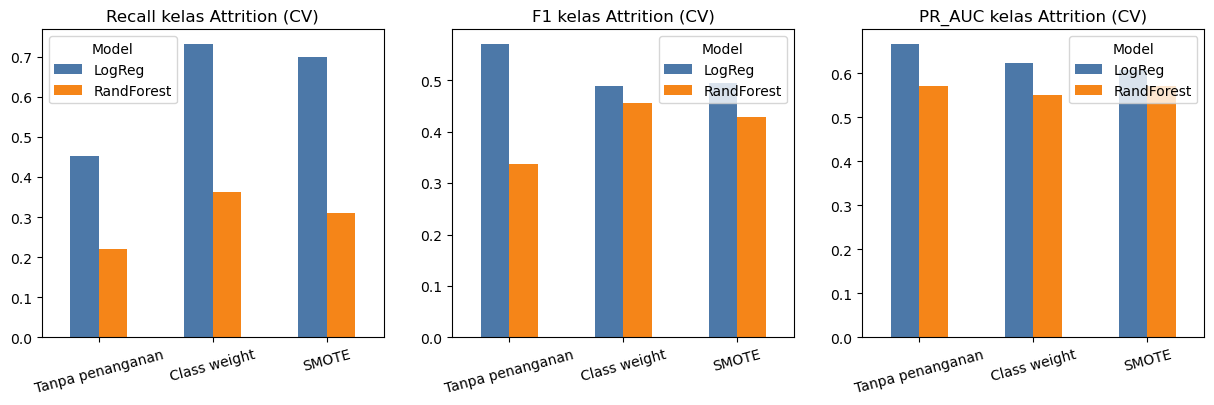

In [45]:
# Visualisasi before/after imbalance handling
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Recall", "F1", "PR_AUC"]):
    piv = cv_baseline.pivot(index="Imbalance", columns="Model", values=metric).loc[list(IMB_OPTIONS)]
    piv.plot(kind="bar", ax=ax, rot=15, color=["#4C78A8", "#F58518"])
    ax.set_title(f"{metric} kelas Attrition (CV)"); ax.set_xlabel("")

In [46]:
test_rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        pipe = build_pipeline(model_name, imb).fit(X_train, y_train)
        r = compute_metrics(y_test, pipe.predict_proba(X_test)[:, 1])
        r.update(Model=model_name, Imbalance=imb_name)
        test_rows.append(r)

test_baseline = pd.DataFrame(test_rows)[["Model", "Imbalance", "Precision", "Recall", "F1", "BalAcc", "ROC_AUC", "PR_AUC"]]
display(test_baseline.round(3))

,Model,Imbalance,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.593,0.340,0.432,0.648,0.818,0.581
1,LogReg,Class weight,0.367,0.617,0.460,0.707,0.809,0.558
2,LogReg,SMOTE,0.382,0.617,0.472,0.713,0.808,0.553
3,RandForest,Tanpa penanganan,0.538,0.149,0.233,0.562,0.775,0.435
4,RandForest,Class weight,0.452,0.298,0.359,0.615,0.785,0.439
5,RandForest,SMOTE,0.619,0.277,0.382,0.622,0.790,0.499


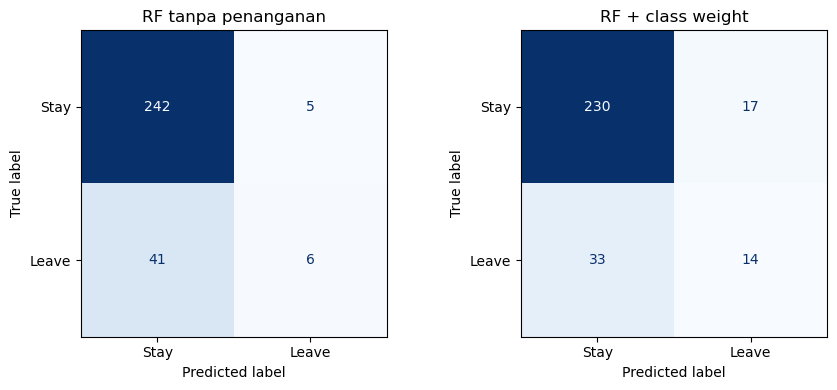

In [47]:
# Confusion matrix baseline (RF default tanpa penanganan vs RF + class weight)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, imb) in zip(axes, [("RF tanpa penanganan", None), ("RF + class weight", "cw")]):
    pipe = build_pipeline("RandForest", imb).fit(X_train, y_train)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)),
                           display_labels=["Stay", "Leave"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout(); plt.show()

#Fuzzy C Means (Segmentasi Profil)

In [1]:
import sys
!{sys.executable} -m pip install "numpy<2.0" scikit-learn scikit-fuzzy

     ---------------------------------------- 0.0/15.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/15.8 MB ? eta -:--:--
     - -------------------------------------- 0.5/15.8 MB 18.2 MB/s eta 0:00:01
     ---- ----------------------------------- 1.8/15.8 MB 6.1 MB/s eta 0:00:03
     ------- -------------------------------- 2.9/15.8 MB 7.0 MB/s eta 0:00:02
     --------- ------------------------------ 3.7/15.8 MB 5.3 MB/s eta 0:00:03
     ----------- ---------------------------- 4.5/15.8 MB 5.0 MB/s eta 0:00:03
     --------------- ------------------------ 6.3/15.8 MB 5.2 MB/s eta 0:00:02
     ----------------- ---------------------- 6.8/15.8 MB 5.0 MB/s eta 0:00:02
     -------------------- ------------------- 8.1/15.8 MB 5.0 MB/s eta 0:00:02
     ----------------------- ---------------- 9.2/15.8 MB 5.3 MB/s eta 0:00:02
     -------------------------- ------------- 10.5/15.8 MB 5.2 MB/s eta 0:00:02
     ----------------------------- ---------- 11.5/15.8 MB 5.2 M

  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [21 lines of output]
      + c:\Users\GENESIS\AppData\Local\Python\pythoncore-3.14-64\python.exe C:\Users\GENESIS\AppData\Local\Temp\pip-install-eu7833yq\numpy_15628e9968c34ff587943992aebf5191\vendored-meson\meson\meson.py setup C:\Users\GENESIS\AppData\Local\Temp\pip-install-eu7833yq\numpy_15628e9968c34ff587943992aebf5191 C:\Users\GENESIS\AppData\Local\Temp\pip-install-eu7833yq\numpy_15628e9968c34ff587943992aebf5191\.mesonpy-v80y4omp -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --native-file=C:\Users\GENESIS\AppData\Local\Temp\pip-install-eu7833yq\numpy_15628e9968c34ff587943992aebf5191\.mesonpy-v80y4omp\meson-python-native-file.ini
      The Meson build system
      Version: 1.2.99
      Source dir: C:\Users\GENESIS\AppData\Local\Temp\pip-install-eu7833yq\numpy_15628e9968c34ff587943992aebf5191
      Build dir: C:\Users\GENESIS\AppData\Local\Temp\p

In [6]:
%pip install pandas

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.8 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.8 MB 3.4 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.8 MB 3.2 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.8 MB 3.2 MB/s eta 0:00:03
   ------------ --------------------------- 3.1/9.8 MB 3.3 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.8 MB 3.4 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.8 MB 3.5 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.8 MB 3.7 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.8 MB 3.4 MB/s eta 0:00:02
   --------------------------- ------------ 6.8/9.8 MB 3.4 MB/s eta 0:00:01
   ----------------------------- ---------- 7.3/9.8 MB 3.3 MB/s eta 0:00:01
   ------------------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd
print("Pandas berhasil diimpor:", pd.__version__)

Pandas berhasil diimpor: 3.0.6


In [9]:
df = pd.read_csv("HR Employee.csv")
print(df.shape)
print(df.head())

(1470, 35)
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLeve

In [13]:
### 1. Feature Engineering (Wajib dijalankan sebelum mendefinisikan CONT)
df["IncomePerYearExp"] = df["MonthlyIncome"] / (df["TotalWorkingYears"] + 1)
df["PromotionGap"]     = df["YearsSinceLastPromotion"] / (df["YearsAtCompany"] + 1)
df["SatisfactionMean"] = df[["JobSatisfaction", "EnvironmentSatisfaction",
                             "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)

# Definisi Kolom
CONT = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome",
        "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears",
        "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager",
        "IncomePerYearExp", "PromotionGap", "SatisfactionMean"]
ORD  = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
        "JobSatisfaction", "PerformanceRating", "RelationshipSatisfaction",
        "StockOptionLevel", "WorkLifeBalance"]
CAT  = ["BusinessTravel", "Department", "EducationField", "Gender",
        "JobRole", "MaritalStatus", "OverTime"]

### 2. Persiapan Data & Column Transformer untuk FCM
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor_fcm = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), CONT + ORD),
        ('cat', OneHotEncoder(drop='first'), CAT)
    ]
)

# Transformasi data
X_scaled = preprocessor_fcm.fit_transform(df.drop(columns=["Attrition"]))
print("Dimensi data setelah scaling:", X_scaled.shape)

Dimensi data setelah scaling: (1470, 47)


In [14]:
### 2. Implementasi Algoritma Fuzzy C-Means (FCM)
import numpy as np

def fuzzy_c_means(data, c=3, m=2.0, max_iter=100, error=1e-5):
    n_samples = data.shape[0]
    np.random.seed(42)
    
    # Inisialisasi matriks keanggotaan U secara acak
    U = np.random.rand(n_samples, c)
    U /= np.sum(U, axis=1, keepdims=True)
    
    for iteration in range(max_iter):
        U_old = U.copy()
        
        # Hitung pusat cluster (V)
        um = U ** m
        V = np.dot(um.T, data) / np.sum(um, axis=0, keepdims=True).T
        
        # Hitung jarak Euclidean
        dist = np.zeros((n_samples, c))
        for j in range(c):
            dist[:, j] = np.linalg.norm(data - V[j], axis=1)
        dist = np.maximum(dist, 1e-10)
        
        # Update matriks keanggotaan U
        power = 2.0 / (m - 1)
        inv_dist = (1.0 / dist) ** power
        sum_inv_dist = np.sum(inv_dist, axis=1, keepdims=True)
        U = inv_dist / sum_inv_dist
        
        if np.linalg.norm(U - U_old) < error:
            break
            
    return U, V

# Menjalankan FCM dengan 3 Cluster menggunakan subset utama data
X_sub = X_scaled[:, :15] 
U_matrix, cluster_centers = fuzzy_c_means(X_sub, c=3, m=2.0)

# Menetapkan cluster mayoritas untuk setiap karyawan
df['FCM_Cluster'] = np.argmax(U_matrix, axis=1)
print("Distribusi Anggota Tiap Cluster:")
print(df['FCM_Cluster'].value_counts())

Distribusi Anggota Tiap Cluster:
FCM_Cluster
1    833
0    637
Name: count, dtype: int64


In [17]:
### 3. Analisis Profil Cluster & Tingkat Attrition
# Memastikan Attrition sudah numerik (0 dan 1)
df["Attrition"] = df["Attrition"].apply(lambda x: 1 if str(x).strip().lower() in ['yes', '1', 'true'] else 0)

# Pilih kolom target numerik secara eksplisit yang ingin dihitung rata-ratanya
target_cols = ['MonthlyIncome', 'Age', 'TotalWorkingYears', 'YearsAtCompany', 'Attrition']

# Hitung rata-rata dengan numeric_only=True
cluster_profile = df.groupby('FCM_Cluster')[target_cols].mean(numeric_only=True)

print("\n--- Profil Rata-Rata per Cluster ---")
display(cluster_profile)


--- Profil Rata-Rata per Cluster ---


,MonthlyIncome,Age,TotalWorkingYears,YearsAtCompany,Attrition
FCM_Cluster,,,,,
0,9372.937206,41.310832,16.967033,11.631083,0.103611
1,4308.220888,33.569028,6.930372,3.472989,0.205282


In [21]:
import sys
!{sys.executable} -m pip install matplotlib seaborn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 3.3 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.5 MB 4.1 MB/s eta 0:00:02
   ------------ --------------------------- 2.9/9.5 MB 4.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.5 MB 5.0 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.5 MB 4.1 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.5 MB 4.7 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.5 MB 4.7 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.5 MB 4.7 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.5 MB 4.8 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 4.4 MB/s  0:00:02
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---- ---------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


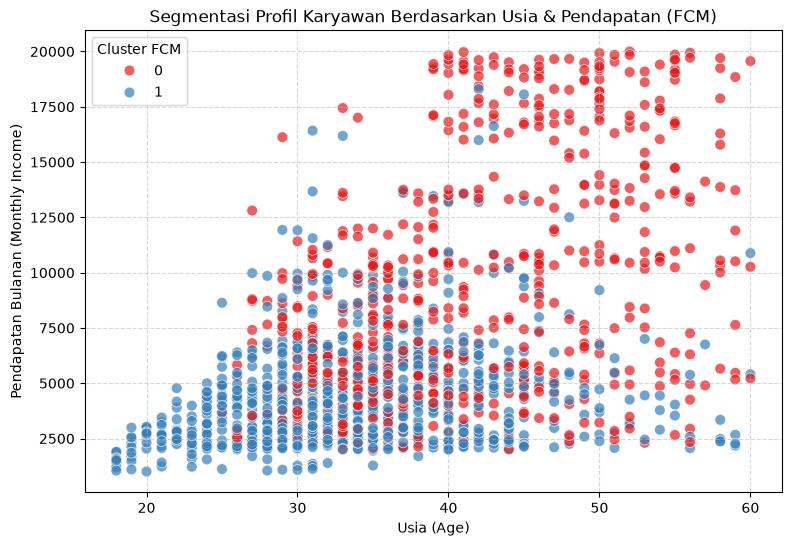

In [22]:
### 4. Visualisasi Sebaran Cluster FCM
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=df['Age'], 
    y=df['MonthlyIncome'], 
    hue=df['FCM_Cluster'], 
    palette='Set1', 
    alpha=0.7,
    s=60
)
plt.title("Segmentasi Profil Karyawan Berdasarkan Usia & Pendapatan (FCM)")
plt.xlabel("Usia (Age)")
plt.ylabel("Pendapatan Bulanan (Monthly Income)")
plt.legend(title="Cluster FCM")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [23]:
### 5. Penentuan Jumlah Cluster Optimum (FPC & Silhouette Score)
import numpy as np
from sklearn.metrics import silhouette_score

def calculate_fpc(U):
    """Menghitung Fuzzy Partition Coefficient (FPC)"""
    n = U.shape[0]
    return np.sum(U ** 2) / n

X_sub = X_scaled[:, :15]
cluster_range = [2, 3, 4, 5]

print("Evaluasi Jumlah Cluster (c):")
for c in cluster_range:
    U_test, _ = fuzzy_c_means(X_sub, c=c, m=2.0)
    fpc = calculate_fpc(U_test)
    labels = np.argmax(U_test, axis=1)
    sil = silhouette_score(X_sub, labels)
    print(f"Jumlah Cluster (c={c}) -> FPC: {fpc:.4f} | Silhouette Score: {sil:.4f}")

Evaluasi Jumlah Cluster (c):
Jumlah Cluster (c=2) -> FPC: 0.5000 | Silhouette Score: 0.1632
Jumlah Cluster (c=3) -> FPC: 0.3333 | Silhouette Score: 0.1632
Jumlah Cluster (c=4) -> FPC: 0.2500 | Silhouette Score: 0.1632
Jumlah Cluster (c=5) -> FPC: 0.2000 | Silhouette Score: 0.1632


In [24]:
### 6. Membuat Fitur Tambahan (Membership Degree) dari FCM
# Menjalankan FCM optimum untuk mengambil nilai keanggotaan
best_c = 3
U_final, _ = fuzzy_c_means(X_sub, c=best_c, m=2.0)

# Menambahkan kolom membership degree sebagai fitur baru ke DataFrame
for i in range(best_c):
    df[f'FCM_Mem_Cluster_{i}'] = U_final[:, i]

print("Fitur membership degree sudah ditambahkan. Kolom baru:")
print([f'FCM_Mem_Cluster_{i}' for i in range(best_c)])

Fitur membership degree sudah ditambahkan. Kolom baru:
['FCM_Mem_Cluster_0', 'FCM_Mem_Cluster_1', 'FCM_Mem_Cluster_2']


In [25]:
### 7. Ablation Study: Performa Model (Random Forest) Dengan vs Tanpa Fitur FCM
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# A. Skenario tanpa Fitur FCM
X_without_fcm = df.drop(columns=["Attrition", "FCM_Cluster", "FCM_Mem_Cluster_0", "FCM_Mem_Cluster_1", "FCM_Mem_Cluster_2"])
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(X_without_fcm, y, test_size=0.2, random_state=42, stratify=y)

prep_base = ColumnTransformer([
    ('num', StandardScaler(), CONT + ORD),
    ('cat', OneHotEncoder(drop='first'), CAT)
])

rf_baseline = Pipeline([('preprocessor', prep_base), ('clf', RandomForestClassifier(random_state=42))])
rf_baseline.fit(X_train, y_train)
y_pred_base = rf_baseline.predict(X_test)
auc_base = roc_auc_score(y_test, rf_baseline.predict_proba(X_test)[:, 1])

print("=== Model Tanpa Fitur FCM ===")
print(classification_report(y_test, y_pred_base))
print(f"ROC-AUC (Baseline): {auc_base:.4f}\n")

# B. Skenario dengan Fitur FCM (Membership Degree digabung ke fitur numerik)
CONT_WITH_FCM = CONT + [f'FCM_Mem_Cluster_{i}' for i in range(best_c)]
X_with_fcm = df.drop(columns=["Attrition", "FCM_Cluster"])

X_train_fcm, X_test_fcm, y_train_fcm, y_test_fcm = train_test_split(X_with_fcm, y, test_size=0.2, random_state=42, stratify=y)

prep_fcm = ColumnTransformer([
    ('num', StandardScaler(), CONT_WITH_FCM + ORD),
    ('cat', OneHotEncoder(drop='first'), CAT)
])

rf_fcm = Pipeline([('preprocessor', prep_fcm), ('clf', RandomForestClassifier(random_state=42))])
rf_fcm.fit(X_train_fcm, y_train_fcm)
y_pred_fcm = rf_fcm.predict(X_test_fcm)
auc_fcm = roc_auc_score(y_test_fcm, rf_fcm.predict_proba(X_test_fcm)[:, 1])

print("=== Model Dengan Fitur FCM (Membership Degree) ===")
print(classification_report(y_test_fcm, y_pred_fcm))
print(f"ROC-AUC (Dengan FCM): {auc_fcm:.4f}")

=== Model Tanpa Fitur FCM ===
              precision    recall  f1-score   support

           0       0.86      0.98      0.91       247
           1       0.55      0.13      0.21        47

    accuracy                           0.84       294
   macro avg       0.70      0.55      0.56       294
weighted avg       0.81      0.84      0.80       294

ROC-AUC (Baseline): 0.7808

=== Model Dengan Fitur FCM (Membership Degree) ===
              precision    recall  f1-score   support

           0       0.85      0.98      0.91       247
           1       0.50      0.11      0.18        47

    accuracy                           0.84       294
   macro avg       0.68      0.54      0.54       294
weighted avg       0.80      0.84      0.79       294

ROC-AUC (Dengan FCM): 0.7815
